# **ЛАБОРАТОРНА РОБОТА 8**
## **Prac 08.2**

In [9]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import Model
from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

## **1. Завантаження та підготовка даних**

In [2]:
(x_train, y_train), (x_test, y_test) = (tf.keras.datasets.fashion_mnist.load_data())

num_classes = 10
size = x_train.shape[1]

print('Навчальна вибірка:', len(y_train), 'зображень')
print('Тестова вибірка:', len(y_test), 'зображень')
print('Розмір навчальної вибірки:', x_train.shape)

Навчальна вибірка: 60000 зображень
Тестова вибірка: 10000 зображень
Розмір навчальної вибірки: (60000, 28, 28)


### Візуалізація

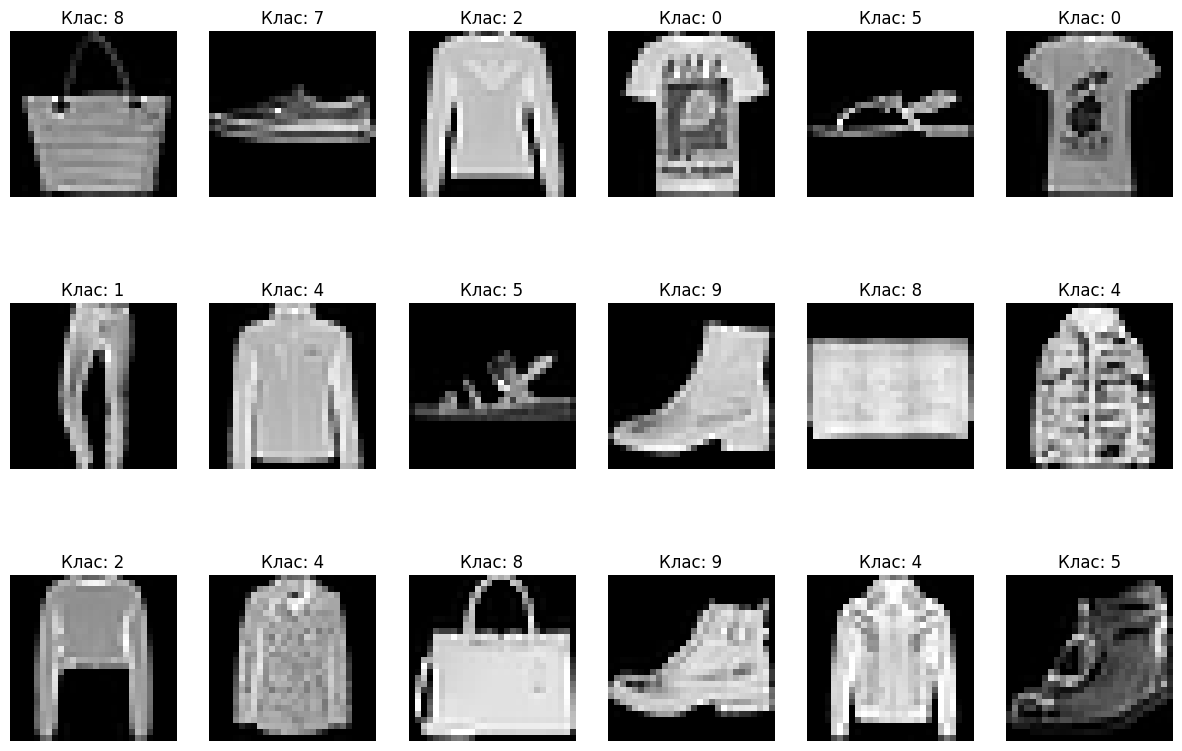

In [ ]:
cnt = 1

for r in range(3):
    for c in range(6):
        
        idx = np.random.randint(len(x_train))

        plt.subplot(3, 6, cnt)
        plt.imshow(x_train[idx], cmap='gray')
        plt.title(f'Клас: {y_train[idx]}')
        plt.axis('off')

        cnt += 1

plt.show()

### Нормалізація пікселів та зміна розмірності даних для чорно-білих зображень

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

## **2. Створення базової моделі**

In [14]:
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding='same')(inputs)
net = Flatten()(net)
net = Dense(128)(net)
outputs = Dense(10, activation="softmax")(net)

model = Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,213,002 (12.26 MB)

 Trainable params: 3,213,002 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

### Навчання моделі

In [ ]:
epochs = 50
batch_size = 64

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_test, y_test)
)

Epoch 1/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 89s 93ms/step - accuracy: 0.8620 - loss: 0.3981 - val_accuracy: 0.8831 - val_loss: 0.3272
Epoch 2/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 101s 107ms/step - accuracy: 0.9059 - loss: 0.2628 - val_accuracy: 0.8889 - val_loss: 0.3047
Epoch 3/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 118s 125ms/step - accuracy: 0.9212 - loss: 0.2200 - val_accuracy: 0.8916 - val_loss: 0.3072
Epoch 4/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 116s 123ms/step - accuracy: 0.9320 - loss: 0.1907 - val_accuracy: 0.8908 - val_loss: 0.3319
Epoch 5/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 112s 119ms/step - accuracy: 0.9407 - loss: 0.1666 - val_accuracy: 0.8934 - val_loss: 0.3452
Epoch 6/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 113s 121ms/step - accuracy: 0.9492 - loss: 0.1466 - val_accuracy: 0.8922 - val_loss: 0.3657
Epoch 7/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 117s 124ms/step - accuracy: 0.9545 - loss: 0.1306 - val_accuracy: 0.8885 - val_loss: 0.4009
Epoch 8/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 111s 118ms/step - accuracy: 0.9601 - l

### Граіфки функції втрат та точності класифікації

In [16]:
def plot_history(history):
    
    h = history.history
    epochs_range = range(len(h['loss']))

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, h['loss'], '.-')
    plt.plot(epochs_range, h['val_loss'], '.-')
    plt.grid(True)
    plt.xlabel('Епоха')
    plt.ylabel('Втрати')
    plt.title('Функція втрат')
    plt.legend(['Навчання', 'Валідація'])

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, h['accuracy'], '.-')
    plt.plot(epochs_range, h['val_accuracy'], '.-')
    plt.grid(True)
    plt.xlabel('Епоха')
    plt.ylabel('Точність')
    plt.title('Точність класифікації')
    plt.legend(['Навчання', 'Валідація'])

    plt.tight_layout()
    plt.show()

    print('Точність на навчанні:', h['accuracy'][-1])
    print('Точність на валідації:', h['val_accuracy'][-1])

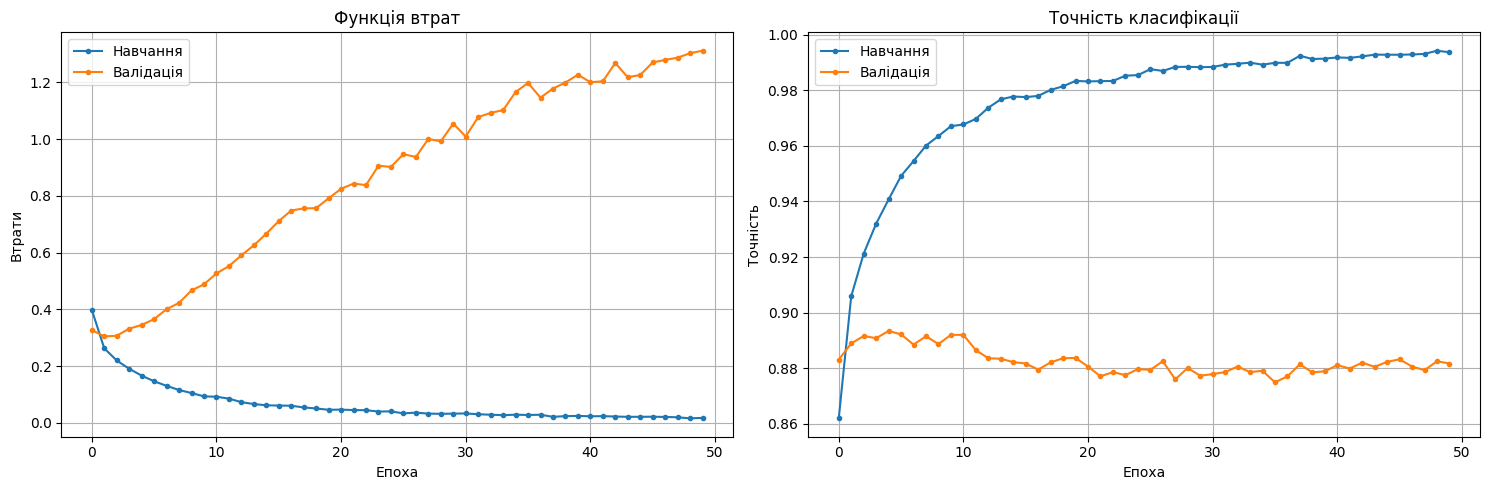

Точність на навчанні: 0.9937000274658203
Точність на валідації: 0.8816999793052673


In [17]:
plot_history(history)

## **3. Покращення моделі**
- Додано додаткові згорткові шари (Conv2D) для виділення ознак зображень.
- Додано BatchNormalization для стабілізації та прискорення навчання.
- Додано MaxPooling2D для зменшення розмірності карт ознак.
- Використано Dropout для зменшення перенавчання.
- Додано L2-регуляризацію для обмеження величини ваг моделі.

In [7]:
inputs = Input(shape=(28, 28, 1))

net = Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
net = BatchNormalization()(net)
net = Conv2D(32, (3, 3), padding='same', activation='relu')(net)
net = BatchNormalization()(net)
net = MaxPooling2D((2, 2))(net)
net = Dropout(0.25)(net)

net = Conv2D(64, (3, 3), padding='same', activation='relu')(net)
net = BatchNormalization()(net)
net = Conv2D(64, (3, 3), padding='same', activation='relu')(net)
net = BatchNormalization()(net)
net = MaxPooling2D((2, 2))(net)
net = Dropout(0.25)(net)

net = Flatten()(net)
net = Dense(64, activation='relu', kernel_regularizer=l2(0.001))(net)
net = Dropout(0.4)(net)

outputs = Dense(10, activation='softmax')(net)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 267,178 (1.02 MB)

 Trainable params: 266,794 (1.02 MB)

 Non-trainable params: 384 (1.50 KB)

### Навчання моделі

In [ ]:
epochs = 50
batch_size = 64

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_test, y_test),
    callbacks=[early_stopping]
)

Epoch 1/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 202s 207ms/step - accuracy: 0.7811 - loss: 0.7254 - val_accuracy: 0.8708 - val_loss: 0.4534
Epoch 2/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 190s 202ms/step - accuracy: 0.8590 - loss: 0.4877 - val_accuracy: 0.8892 - val_loss: 0.4017
Epoch 3/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 186s 198ms/step - accuracy: 0.8793 - loss: 0.4259 - val_accuracy: 0.9017 - val_loss: 0.3787
Epoch 4/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 193s 205ms/step - accuracy: 0.8927 - loss: 0.3975 - val_accuracy: 0.8992 - val_loss: 0.3785
Epoch 5/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 231s 246ms/step - accuracy: 0.8990 - loss: 0.3786 - val_accuracy: 0.9059 - val_loss: 0.3619
Epoch 6/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 220s 235ms/step - accuracy: 0.9073 - loss: 0.3638 - val_accuracy: 0.9155 - val_loss: 0.3330
Epoch 7/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 209s 223ms/step - accuracy: 0.9136 - loss: 0.3491 - val_accuracy: 0.9134 - val_loss: 0.3460
Epoch 8/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.9150 -

### Граіфки функції втрат та точності класифікації

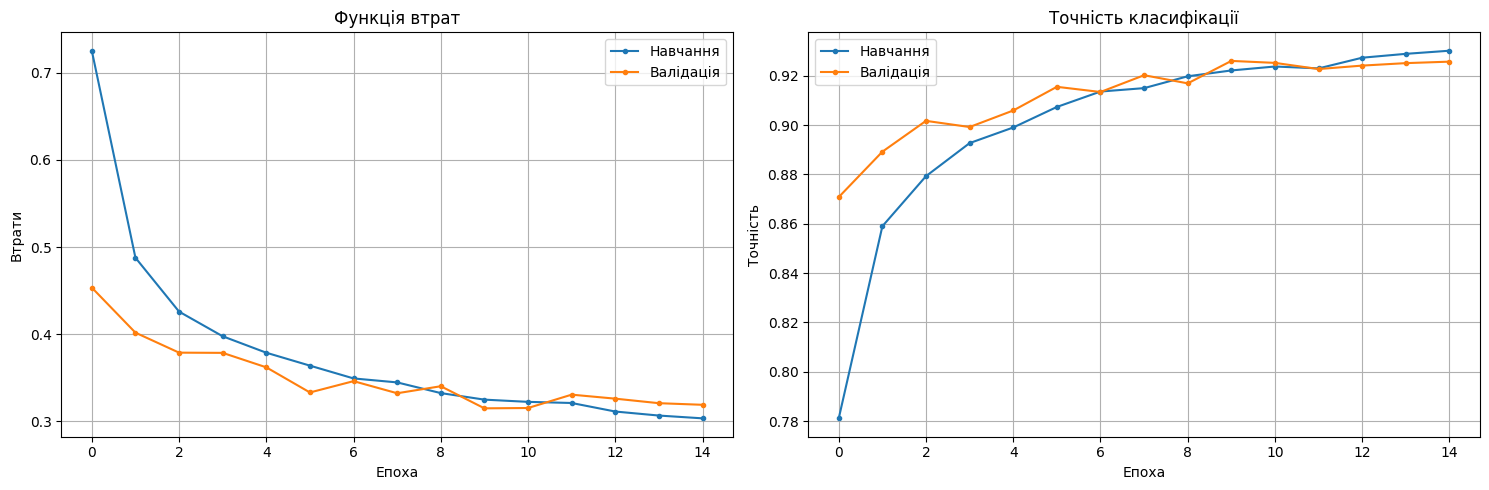

Точність на навчанні: 0.9301333427429199
Точність на валідації: 0.9257000088691711


In [13]:
plot_history(history)